# Previsão do valor mediano de imóveis na Califórnia — Regressão supervisionada

**MBA em Ciência de Dados — Aprendizado de Máquina Supervisionado (Prof. Caio Ponte, Turma 12)**
**Projeto final** · Integrantes: _(preencher nomes do grupo)_

### Resumo em 30 segundos
- **Pergunta:** quanto vale, em média, uma casa em determinada região da Califórnia?
- **Dados:** censo de 1990, 20.640 regiões, 9 características de cada uma (renda, localização, tamanho etc.).
- **Como:** limpamos e preparamos os dados, treinamos 4 modelos de aprendizado de máquina e comparamos com honestidade.
- **Resultado:** o melhor modelo (**Gradient Boosting**) erra em média **≈ US$ 27 mil (≈ 16%)** e explica **82,5%** da variação dos preços.

### Como ler este notebook
Cada etapa começa com uma **"Em uma frase"**, cada gráfico é seguido de uma **"Leitura"** (o que ele mostra) e cada etapa termina com um **resumo** do que foi decidido e por quê. As cinco etapas seguem o que o projeto pede:
1. Definição do problema
2. Análise exploratória dos dados (EDA)
3. Pré-processamento dos dados
4. Treinamento dos modelos (3 famílias + ajuste de hiperparâmetros)
5. Avaliação, benchmark e conclusão

### Glossário rápido
| Termo | O que significa aqui |
|---|---|
| **Feature** (atributo) | Cada característica que o modelo usa para prever (ex.: renda, latitude). |
| **Target** (alvo) | O que queremos prever: o valor mediano das casas. |
| **Treino / Teste** | Treino = dados com que o modelo aprende. Teste = dados que ele nunca viu, usados só no fim (a "prova final"). |
| **Validação cruzada** | Dividir o treino em partes e alternar quem é "prova" e quem é "estudo" (os "simulados"), para escolher bons ajustes sem tocar no teste. |
| **Hiperparâmetro** | "Botão" do modelo, definido antes do treino (ex.: número de vizinhos do KNN). |
| **Overfitting** | O modelo decora o treino e vai mal em dados novos. |
| **Underfitting** | O modelo é simples demais e vai mal até no treino. |
| **Pipeline** | A "receita" completa (preparar os dados e treinar), aplicada sempre na mesma ordem. |
| **Data leakage** (vazamento) | Deixar informação do teste "vazar" para o treino, como olhar o gabarito antes da prova. |
| **Outlier** | Valor muito fora do comum. |
| **One-hot** | Transformar uma categoria em colunas de 0 e 1. |
| **Padronização** | Colocar as variáveis na mesma escala (média 0, desvio 1). |

> Para rodar: deixe o arquivo `california_house_price.csv` na mesma pasta do notebook e execute as células em ordem (Kernel → Restart & Run All).

---
# 1. Definição do problema

> **Em uma frase:** antes de qualquer código, dizemos **o que queremos prever, com quais dados e para quê**.

### 1.1 Contexto
Em mercados imobiliários, precificar um imóvel ou uma região de forma consistente é uma tarefa recorrente para imobiliárias, bancos (avaliação de garantia de financiamento), seguradoras e poder público. Aqui usamos dados **públicos** do censo norte-americano de 1990 sobre a Califórnia, que reúnem características demográficas e geográficas de cada região e o valor mediano das casas ali.

### 1.2 Problema
- **Tipo de problema:** **regressão supervisionada** (o alvo é um valor numérico contínuo).
- **O que cada linha representa:** um _block group_ do censo (a menor unidade geográfica com dados amostrais do Census Bureau, tipicamente 600 a 3.000 pessoas). **Não é um imóvel individual.** Por isso, `total_rooms`, `population` etc. são totais da região.
- **Pergunta:** dadas as características de uma região (renda, idade das casas, localização, tamanho, proximidade do mar), qual é o **valor mediano das casas** dessa região?

### 1.3 Motivação
Um modelo que estima o valor mediano a partir de variáveis simples permite (i) ter uma referência de preço para regiões sem avaliação recente, (ii) identificar regiões cujo preço está fora do esperado e (iii) entender **quais fatores mais pesam** no preço, apoiando decisões de investimento e crédito.

### 1.4 Origem e formato dos dados
- **Origem:** censo de 1990 da Califórnia (repositório StatLib; Pace & Barry, 1997), na versão popularizada em arquivo CSV (`california_house_price.csv`).
- **Formato original:** CSV, 20.640 linhas e 10 colunas (9 numéricas e 1 categórica).

### 1.5 Dicionário de dados

| Coluna | Descrição | Papel no modelo |
|---|---|---|
| `longitude` | Longitude do block group | feature |
| `latitude` | Latitude do block group | feature |
| `housing_median_age` | Idade mediana das casas (anos) | feature |
| `total_rooms` | Total de cômodos no block group | feature |
| `total_bedrooms` | Total de quartos no block group (tem valores nulos) | feature |
| `population` | População do block group | feature |
| `households` | Número de domicílios | feature |
| `median_income` | Renda mediana dos domicílios (em dezenas de milhares de US$) | feature |
| `ocean_proximity` | Proximidade do oceano (categórica: `<1H OCEAN`, `INLAND`, `NEAR OCEAN`, `NEAR BAY`, `ISLAND`) | feature |
| `median_house_value` | **Valor mediano das casas (US$)** | **target (alvo)** |

Na etapa 3 também **criaremos** três features derivadas: `rooms_per_household`, `bedrooms_per_room` e `population_per_household`.

In [1]:
import warnings
import time
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.model_selection import train_test_split, KFold, GridSearchCV, RandomizedSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.dummy import DummyRegressor
from sklearn.decomposition import PCA
from sklearn.feature_selection import f_regression, mutual_info_regression
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, confusion_matrix, classification_report,
                             mean_absolute_error, mean_squared_error, r2_score,
                             mean_absolute_percentage_error, median_absolute_error)

SEED = 42                      # semente fixa para os resultados serem reproduzíveis
sns.set_theme(style='whitegrid')
plt.rcParams.update({'figure.dpi': 100, 'axes.titlesize': 12, 'axes.labelsize': 10})
pd.set_option('display.float_format', lambda v: f'{v:,.3f}')

In [2]:
df = pd.read_csv('california_house_price.csv')
print('Linhas x colunas:', df.shape)
df.head()

Linhas x colunas: (20640, 10)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.230,37.880,41.000,880.000,129.000,322.000,126.000,8.325,"452,600.000",NEAR BAY
1,-122.220,37.860,21.000,"7,099.000","1,106.000","2,401.000","1,138.000",8.301,"358,500.000",NEAR BAY
2,-122.240,37.850,52.000,"1,467.000",190.000,496.000,177.000,7.257,"352,100.000",NEAR BAY
3,-122.250,37.850,52.000,"1,274.000",235.000,558.000,219.000,5.643,"341,300.000",NEAR BAY
4,-122.250,37.850,52.000,"1,627.000",280.000,565.000,259.000,3.846,"342,200.000",NEAR BAY


---
# 2. Análise Exploratória dos Dados (EDA)

> **Em uma frase:** antes de treinar qualquer modelo, **olhamos os dados com calma** para descobrir o que têm de bom e de problemático. _Analogia: é ler o enunciado e dar uma olhada geral na prova antes de responder._

Itens cobertos: **estatísticas descritivas, distribuição das variáveis, identificação de outliers, matriz de correlações, mapa geográfico e redução de dimensionalidade (PCA)**.

### 2.1 Estrutura, tipos e valores nulos

In [3]:
df.info()
print()
print('Valores nulos por coluna:')
print(df.isna().sum()[df.isna().sum() > 0])

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.6 MB

Valores nulos por coluna:
total_bedrooms    207
dtype: int64


### 2.2 Estatísticas descritivas

In [4]:
num_cols = df.select_dtypes(include='number').columns.tolist()
desc = df[num_cols].describe().T
desc['mediana'] = df[num_cols].median()
desc['assimetria'] = df[num_cols].skew()
desc[['count', 'mean', 'mediana', 'std', 'min', '25%', '75%', 'max', 'assimetria']]

,count,mean,mediana,std,min,25%,75%,max,assimetria
longitude,"20,640.000",-119.570,-118.490,2.004,-124.350,-121.800,-118.010,-114.310,-0.298
latitude,"20,640.000",35.632,34.260,2.136,32.540,33.930,37.710,41.950,0.466
housing_median_age,"20,640.000",28.639,29.000,12.586,1.000,18.000,37.000,52.000,0.060
total_rooms,"20,640.000","2,635.763","2,127.000","2,181.615",2.000,"1,447.750","3,148.000","39,320.000",4.147
total_bedrooms,"20,433.000",537.871,435.000,421.385,1.000,296.000,647.000,"6,445.000",3.460
population,"20,640.000","1,425.477","1,166.000","1,132.462",3.000,787.000,"1,725.000","35,682.000",4.936
households,"20,640.000",499.540,409.000,382.330,1.000,280.000,605.000,"6,082.000",3.410
median_income,"20,640.000",3.871,3.535,1.900,0.500,2.563,4.743,15.000,1.647
median_house_value,"20,640.000","206,855.817","179,700.000","115,395.616","14,999.000","119,600.000","264,725.000","500,001.000",0.978


**Leitura:** `total_rooms`, `total_bedrooms`, `population` e `households` têm média bem acima da mediana e assimetria alta (cauda longa à direita), o que sugere uma transformação logarítmica depois. Outro ponto: o máximo de `median_house_value` é 500.001, o que indica que o valor foi **limitado (censurado) em US$ 500 mil** (veja a seção 2.3).

### 2.3 Distribuição das variáveis

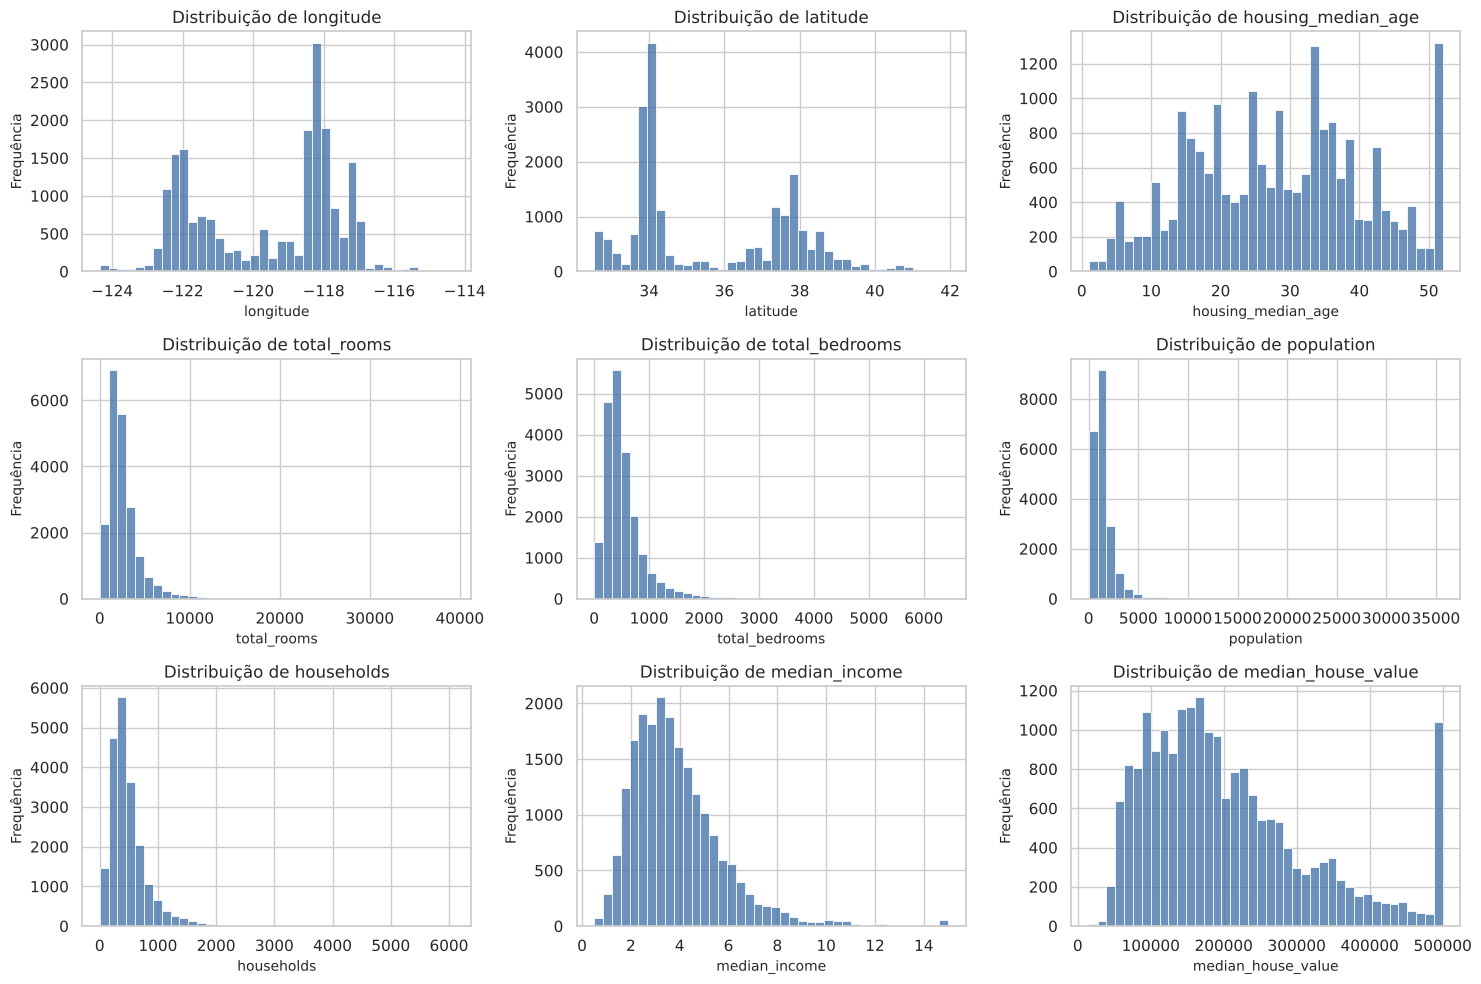

Registros com valor no teto de US$ 500 mil: 992 (4.8% da base)


In [5]:
fig, axes = plt.subplots(3, 3, figsize=(15, 10))
for ax, col in zip(axes.ravel(), num_cols):
    sns.histplot(df[col], bins=40, kde=False, ax=ax, color='#3b6ea5')
    ax.set_title(f'Distribuição de {col}')
    ax.set_xlabel(col)
    ax.set_ylabel('Frequência')
plt.tight_layout()
plt.show()

teto = (df['median_house_value'] >= 500000).sum()
print(f'Registros com valor no teto de US$ 500 mil: {teto} ({teto/len(df):.1%} da base)')

**Leitura:** a variável-alvo tem um **pico artificial no teto de US$ 500 mil**: o valor real dessas regiões não é conhecido (dado censurado). Isso afeta o modelo e será tratado na etapa 3. Também há um acúmulo em `housing_median_age = 52`, que parece ser o mesmo tipo de limite superior.

### 2.4 Outliers (boxplots e regra do IQR)

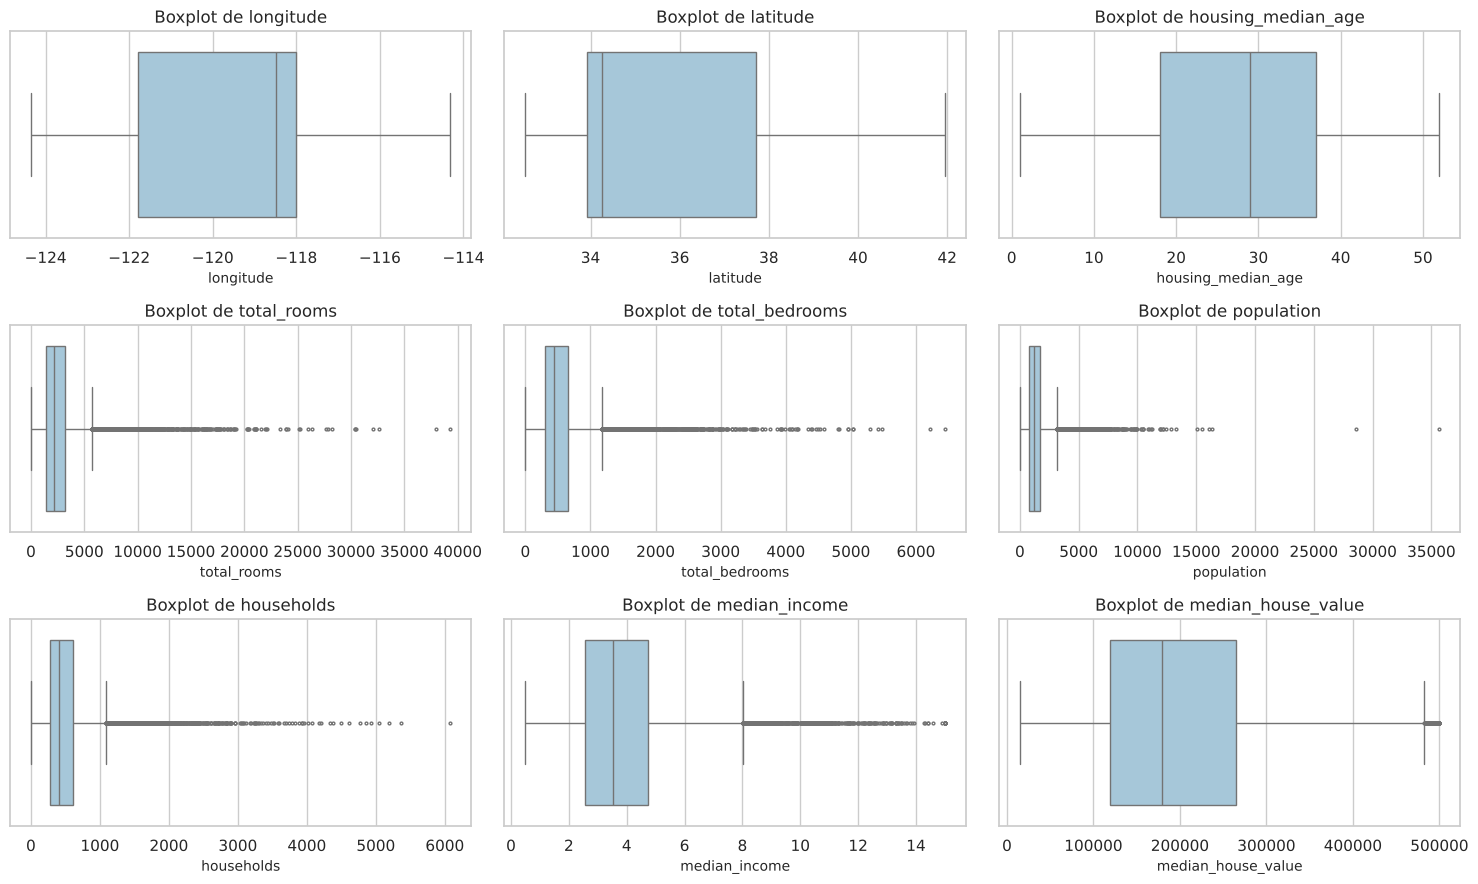

,outliers (regra do IQR),% da base
longitude,0,0.000
latitude,0,0.000
housing_median_age,0,0.000
total_rooms,1287,6.235
total_bedrooms,1271,6.158
population,1196,5.795
households,1220,5.911
median_income,681,3.299
median_house_value,1071,5.189


In [6]:
fig, axes = plt.subplots(3, 3, figsize=(15, 9))
for ax, col in zip(axes.ravel(), num_cols):
    sns.boxplot(x=df[col], ax=ax, color='#9ecae1', fliersize=2)
    ax.set_title(f'Boxplot de {col}')
    ax.set_xlabel(col)
plt.tight_layout()
plt.show()

def contar_outliers_iqr(s):
    q1, q3 = s.quantile([.25, .75])
    iqr = q3 - q1
    return int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum())

tab_out = pd.DataFrame({'outliers (regra do IQR)': {c: contar_outliers_iqr(df[c].dropna()) for c in num_cols}})
tab_out['% da base'] = tab_out['outliers (regra do IQR)'] / len(df) * 100
tab_out

**Leitura:** as variáveis de **tamanho** (`total_rooms`, `total_bedrooms`, `population`, `households`) concentram muitos outliers, o que é esperado, pois block groups grandes têm totais maiores. Isso é diferente de erro de dado, então não removemos tudo pela regra do IQR. Na etapa 3 trataremos só os casos claramente absurdos (por exemplo, mais de 10 moradores por domicílio em média) e reduziremos a influência dos demais com **log + padronização**.

### 2.5 Matriz de correlações

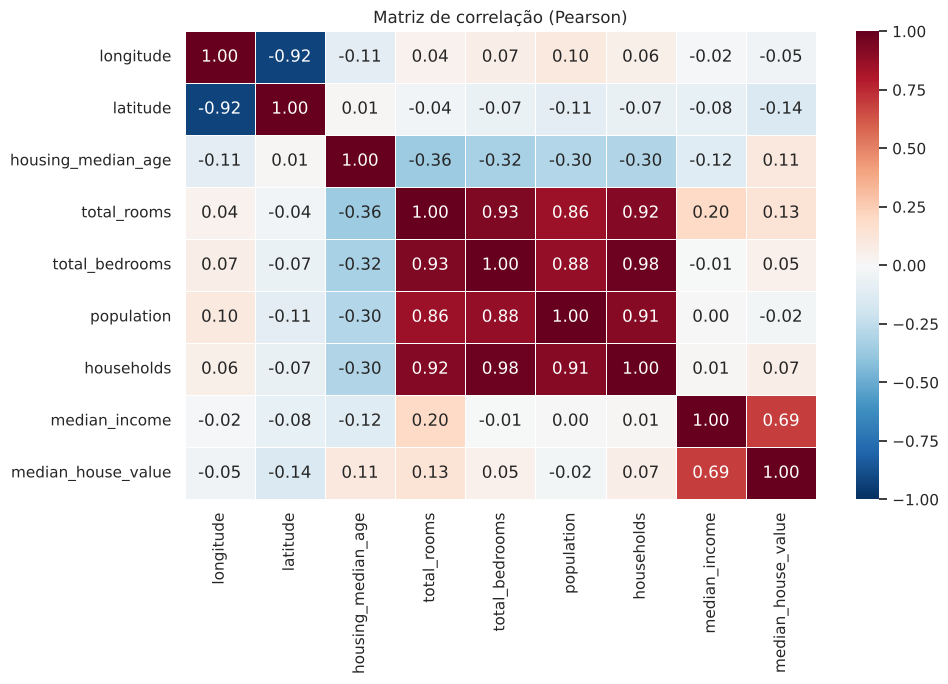

Correlação com o alvo (median_house_value):
median_income         0.688
total_rooms           0.134
housing_median_age    0.106
households            0.066
total_bedrooms        0.050
population           -0.025
longitude            -0.046
latitude             -0.144
Name: median_house_value, dtype: float64


In [7]:
plt.figure(figsize=(10, 7))
corr = df[num_cols].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1, linewidths=.5)
plt.title('Matriz de correlação (Pearson)')
plt.tight_layout()
plt.show()

print('Correlação com o alvo (median_house_value):')
print(corr['median_house_value'].drop('median_house_value').sort_values(ascending=False).round(3))

**Leitura:** `median_income` é de longe a variável mais associada ao preço (correlação por volta de 0,69). Já `total_rooms`, `total_bedrooms`, `population` e `households` são **muito correlacionadas entre si** (multicolinearidade), porque todas medem o "tamanho" do block group. Isso justifica criar variáveis **por domicílio** (razões) na etapa 3.

### 2.6 Relação entre renda, localização e preço

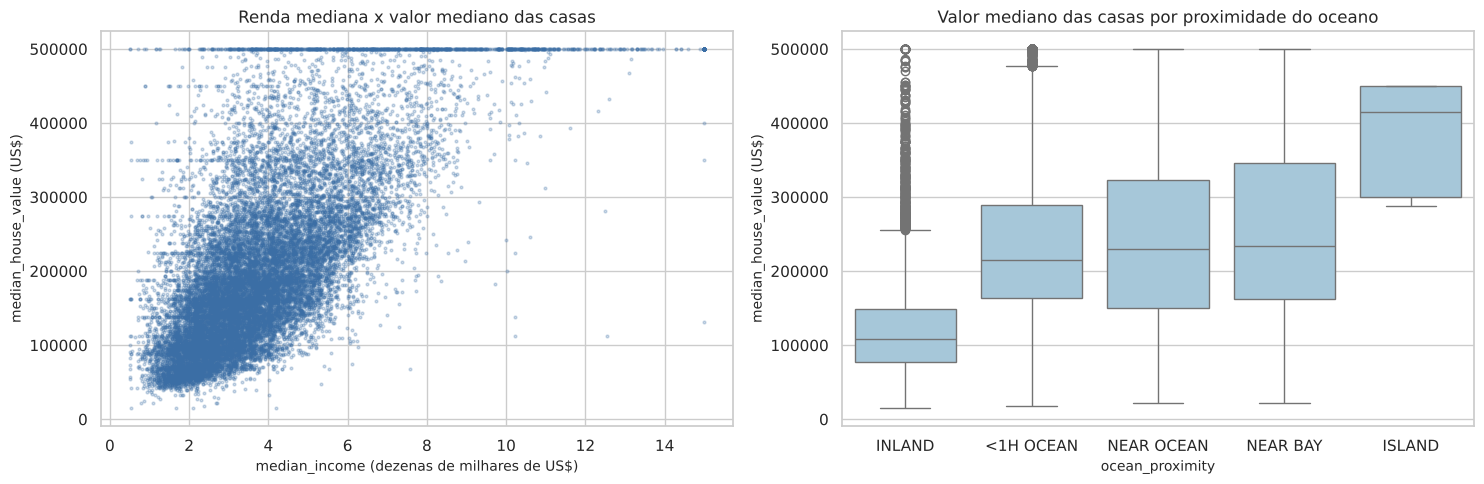

ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].scatter(df['median_income'], df['median_house_value'], s=4, alpha=.25, color='#3b6ea5')
axes[0].set_title('Renda mediana x valor mediano das casas')
axes[0].set_xlabel('median_income (dezenas de milhares de US$)')
axes[0].set_ylabel('median_house_value (US$)')

ordem = df.groupby('ocean_proximity')['median_house_value'].median().sort_values().index
sns.boxplot(data=df, x='ocean_proximity', y='median_house_value', order=ordem, ax=axes[1], color='#9ecae1')
axes[1].set_title('Valor mediano das casas por proximidade do oceano')
axes[1].set_xlabel('ocean_proximity')
axes[1].set_ylabel('median_house_value (US$)')

plt.tight_layout()
plt.show()
print(df['ocean_proximity'].value_counts())

### 2.7 Mapa geográfico

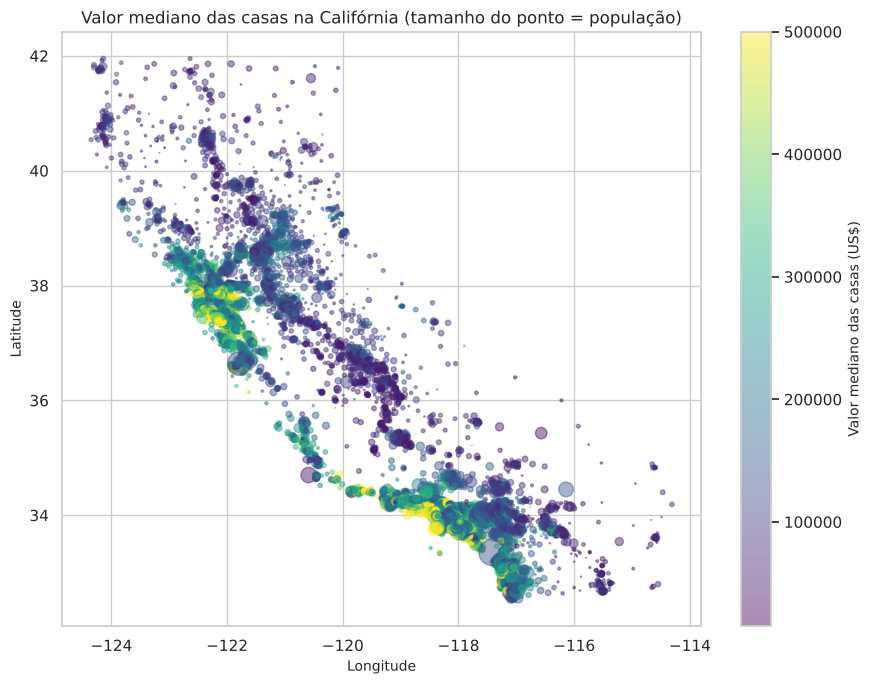

In [9]:
fig, ax = plt.subplots(figsize=(9, 7))
sc = ax.scatter(df['longitude'], df['latitude'], c=df['median_house_value'], s=df['population'] / 100,
                cmap='viridis', alpha=.45)
cb = plt.colorbar(sc, ax=ax)
cb.set_label('Valor mediano das casas (US$)')
ax.set_title('Valor mediano das casas na Califórnia (tamanho do ponto = população)')
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
plt.tight_layout()
plt.show()

**Leitura:** os valores mais altos se concentram na **faixa litorânea**, em especial nas regiões da Baía de São Francisco e de Los Angeles/San Diego; o interior (Central Valley) tem preços menores. Ou seja, `latitude`, `longitude` e `ocean_proximity` carregam informação espacial forte, e modelos não lineares (árvores, KNN) tendem a aproveitá-la melhor do que uma reta.

### 2.8 Redução de dimensionalidade (PCA)

Variância explicada por PC1 e PC2: [0.488 0.238] | total: 0.726


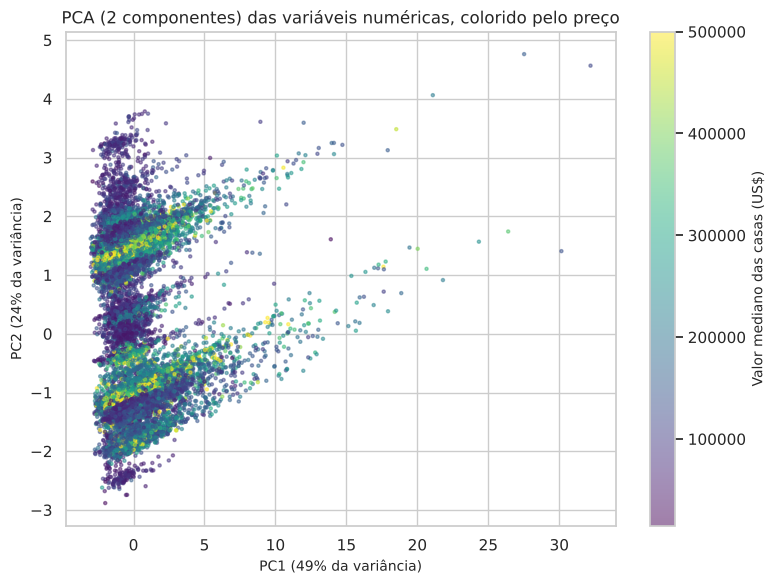

In [10]:
feats_pca = ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms',
             'population', 'households', 'median_income']
Xp = SimpleImputer(strategy='median').fit_transform(df[feats_pca])
Xp = StandardScaler().fit_transform(Xp)

pca = PCA(n_components=2, random_state=SEED)
Z = pca.fit_transform(Xp)
print('Variância explicada por PC1 e PC2:', pca.explained_variance_ratio_.round(3),
      '| total:', pca.explained_variance_ratio_.sum().round(3))

fig, ax = plt.subplots(figsize=(8, 6))
sc = ax.scatter(Z[:, 0], Z[:, 1], c=df['median_house_value'], s=5, cmap='viridis', alpha=.5)
plt.colorbar(sc, ax=ax).set_label('Valor mediano das casas (US$)')
ax.set_title('PCA (2 componentes) das variáveis numéricas, colorido pelo preço')
ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.0%} da variância)')
ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.0%} da variância)')
plt.tight_layout()
plt.show()

**Leitura:** as duas primeiras componentes juntas explicam uma parte relevante da variância, mas **não separam o preço de forma nítida**: as cores aparecem misturadas. Ou seja, o preço não depende de uma única direção linear dos dados, o que reforça a necessidade de modelos capazes de capturar relações não lineares. _(O PCA aqui serve só para visualização; ele não entra no modelo.)_

### Resumo da etapa 2: o que descobrimos e o que vamos fazer

| O que vimos na EDA | Por que importa | O que faremos na etapa 3 |
|---|---|---|
| 207 valores nulos em `total_bedrooms` (1%) | Os modelos não aceitam nulos | Preencher com a mediana |
| O preço "trava" em US$ 500 mil (4,8% da base) | É um limite de coleta: o preço real é desconhecido | Remover essas regiões |
| Variáveis de tamanho com cauda longa e muitos outliers | Poucas regiões enormes distorcem a escala | Aplicar log e padronizar |
| Renda é a variável mais ligada ao preço (correlação 0,69); os totais são muito correlacionados entre si | Os totais medem todos o "tamanho" da região | Criar variáveis por domicílio |
| Preço mais alto no litoral | A localização importa e não funciona como uma reta | Manter latitude, longitude e proximidade do oceano; testar modelos não lineares |
| PCA sem separação nítida | O preço não depende de uma única direção simples | Idem: testar modelos não lineares |

---
# 3. Pré-processamento dos dados

> **Em uma frase:** **arrumar os dados** para que os modelos consigam aprender com eles. _Analogia: é a mise en place da cozinha: lavar, cortar e separar os ingredientes antes de cozinhar._

Itens cobertos: **(a) filtragem e limpeza, (b) valores faltantes, (c) normalização/padronização (log + StandardScaler), (d) variáveis categóricas (OneHotEncoder), (e) engenharia de atributos e (f) análise de relevância de atributos (f_regression)**.

> **Cuidado com vazamento de dados (_data leakage_):** primeiro dividimos treino/teste e **todas** as transformações com parâmetros aprendidos (imputação, escala, encoding) são ajustadas **só no treino**, dentro de um `Pipeline`.

### 3.1 Filtragem e limpeza

In [11]:
n0 = len(df)

# Regra 1: remover registros com o alvo censurado no teto (valor real desconhecido)
mask_teto = df['median_house_value'] < 500001

# Regra 2: remover inconsistências evidentes (domicílios com cômodos ou moradores em quantidade absurda)
rooms_hh = df['total_rooms'] / df['households']
pop_hh = df['population'] / df['households']
mask_valido = (rooms_hh <= 20) & (pop_hh <= 10)

print(f'Registros no teto de US$ 500 mil removidos (alvo censurado): {(~mask_teto).sum()}')
print(f'Registros removidos por inconsistência (rooms/hh > 20 ou pop/hh > 10): {(~mask_valido).sum()}')
print(f'(Registros que violam as duas regras ao mesmo tempo: {((~mask_teto) & (~mask_valido)).sum()})')

df_clean = df[mask_teto & mask_valido].reset_index(drop=True)
print(f'Total removido (sem contar duas vezes): {n0 - len(df_clean)}')
print(f'Base original: {n0} | Base limpa: {len(df_clean)} ({len(df_clean)/n0:.1%} mantido)')

Registros no teto de US$ 500 mil removidos (alvo censurado): 965
Registros removidos por inconsistência (rooms/hh > 20 ou pop/hh > 10): 105
(Registros que violam as duas regras ao mesmo tempo: 5)
Total removido (sem contar duas vezes): 1065
Base original: 20640 | Base limpa: 19575 (94.8% mantido)


**Justificativa:** o teto de US$ 500 mil é um limite de coleta, não um preço real. Treinar com esses valores ensinaria o modelo a "achatar" as previsões nas regiões mais caras. **Consequência prática:** o modelo final **não é adequado para regiões acima de ~US$ 500 mil**. Isso entra na conclusão.

### 3.2 Divisão treino/teste

In [12]:
X = df_clean.drop(columns='median_house_value')
y = df_clean['median_house_value']

# Divisão 80/20 estratificada pela faixa de renda (garante a mesma distribuição da variável mais importante nos dois conjuntos)
faixa_renda = pd.qcut(X['median_income'], q=5, labels=False)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=faixa_renda)

print('Treino:', X_train.shape, '| Teste:', X_test.shape)
print('Valor mediano do alvo -> treino: %.0f | teste: %.0f' % (y_train.median(), y_test.median()))

Treino: (15660, 9) | Teste: (3915, 9)
Valor mediano do alvo -> treino: 173950 | teste: 174100


### 3.3 Valores faltantes

In [13]:
print('Nulos no treino:')
print(X_train.isna().sum()[X_train.isna().sum() > 0])
print(f'\nProporção de nulos em total_bedrooms: {X_train["total_bedrooms"].isna().mean():.2%}')

Nulos no treino:
total_bedrooms    166
dtype: int64

Proporção de nulos em total_bedrooms: 1.06%


**Decisão:** `total_bedrooms` tem ~1% de nulos. Como é pouco e a variável é assimétrica, imputamos pela **mediana do treino** (`SimpleImputer(strategy='median')`), que é robusta a outliers, em vez de descartar linhas.

### 3.4 Engenharia de atributos

In [14]:
def criar_features(X_):
    """Cria variáveis normalizadas por domicílio/cômodo (reduz a multicolinearidade entre as variáveis de tamanho)."""
    X_ = X_.copy()
    X_['rooms_per_household'] = X_['total_rooms'] / X_['households']
    X_['bedrooms_per_room'] = X_['total_bedrooms'] / X_['total_rooms']
    X_['population_per_household'] = X_['population'] / X_['households']
    return X_

amostra = criar_features(X_train)
amostra[['rooms_per_household', 'bedrooms_per_room', 'population_per_household']].describe().T

,count,mean,std,min,25%,50%,75%,max
rooms_per_household,"15,660.000",5.266,1.368,0.846,4.409,5.182,5.954,19.962
bedrooms_per_room,"15,494.000",0.215,0.057,0.100,0.178,0.205,0.241,1.000
population_per_household,"15,660.000",2.943,0.774,0.750,2.447,2.837,3.304,9.955


**Por quê:** os totais (`total_rooms`, `population`...) dependem do tamanho do block group. As razões descrevem o **padrão de moradia** (casas amplas vs. apertadas, famílias grandes vs. pequenas), que é mais informativo sobre o preço.

### 3.5 Padronização, log e codificação categórica (ColumnTransformer + Pipeline)

In [15]:
cols_log = ['total_rooms', 'total_bedrooms', 'population', 'households']      # assimétricas -> log + padronização
cols_num = ['longitude', 'latitude', 'housing_median_age', 'median_income',
            'rooms_per_household', 'bedrooms_per_room', 'population_per_household']  # padronização
cols_cat = ['ocean_proximity']                                                  # one-hot

pipe_log = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('log', FunctionTransformer(np.log1p, feature_names_out='one-to-one')),
    ('scaler', StandardScaler()),
])
pipe_num = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
])

preprocessador = ColumnTransformer([
    ('log', pipe_log, cols_log),
    ('num', pipe_num, cols_num),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cols_cat),
])

def montar_pipeline(modelo):
    """Pipeline completo: criação de features -> pré-processamento -> modelo."""
    return Pipeline([
        ('features', FunctionTransformer(criar_features)),
        ('prep', clone(preprocessador)),
        ('modelo', modelo),
    ])

# Demonstração do que o pré-processamento entrega (ajustado só no treino)
prep_demo = clone(preprocessador)
Xt_demo = prep_demo.fit_transform(criar_features(X_train))
nomes = prep_demo.get_feature_names_out()
print('Matriz final de treino:', Xt_demo.shape)
pd.DataFrame(Xt_demo[:5], columns=nomes).round(2)

Matriz final de treino: (15660, 16)


,log__total_rooms,log__total_bedrooms,log__population,log__households,num__longitude,num__latitude,num__housing_median_age,num__median_income,num__rooms_per_household,num__bedrooms_per_room,num__population_per_household,cat__ocean_proximity_<1H OCEAN,cat__ocean_proximity_INLAND,cat__ocean_proximity_ISLAND,cat__ocean_proximity_NEAR BAY,cat__ocean_proximity_NEAR OCEAN
0,-0.330,-0.600,-0.340,-0.610,1.240,-1.430,-0.270,0.090,0.670,-0.720,0.670,0.000,0.000,0.000,0.000,1.000
1,1.120,1.730,1.150,1.680,0.570,-0.760,-0.750,-0.180,-1.270,1.730,-1.250,1.000,0.000,0.000,0.000,0.000
2,-0.420,-0.610,-0.010,-0.390,-1.430,0.960,1.890,0.220,-0.220,-0.540,1.030,0.000,0.000,0.000,1.000,0.000
3,-0.050,0.260,-0.040,0.310,0.750,-0.850,-0.910,0.110,-0.970,0.820,-0.930,1.000,0.000,0.000,0.000,0.000
4,0.590,0.610,0.400,0.620,1.260,-1.340,1.170,-0.340,-0.140,-0.090,-0.630,0.000,0.000,0.000,0.000,1.000


**Justificativas:**
- **Log + StandardScaler** nas variáveis de tamanho: reduz a assimetria e o peso dos outliers; a padronização é essencial para o **KNN** (baseado em distância) e para o **Ridge** (penalização).
- **StandardScaler** nas demais numéricas: coloca tudo na mesma escala.
- **OneHotEncoder** em `ocean_proximity`: é categórica **sem ordem natural**, então não faz sentido codificá-la como 0,1,2,3 (o modelo interpretaria uma ordem inexistente). `handle_unknown='ignore'` evita erro se aparecer categoria nova.

### 3.6 Relevância dos atributos (seleção univariada: `f_regression` e informação mútua)

,atributo,F-score (linear),Informação mútua (não linear),posição (F),posição (MI)
0,longitude,32.668,0.391,14,1
1,latitude,357.616,0.341,9,2
2,median_income,"10,849.072",0.329,1,3
3,ocean_proximity_INLAND,"5,273.188",0.197,2,4
4,bedrooms_per_room,749.567,0.116,5,5
5,ocean_proximity_<1H OCEAN,"1,364.963",0.099,3,6
6,rooms_per_household,653.300,0.079,6,7
7,population_per_household,"1,031.873",0.063,4,8
8,total_rooms,509.118,0.041,7,9
9,housing_median_age,68.048,0.033,13,10


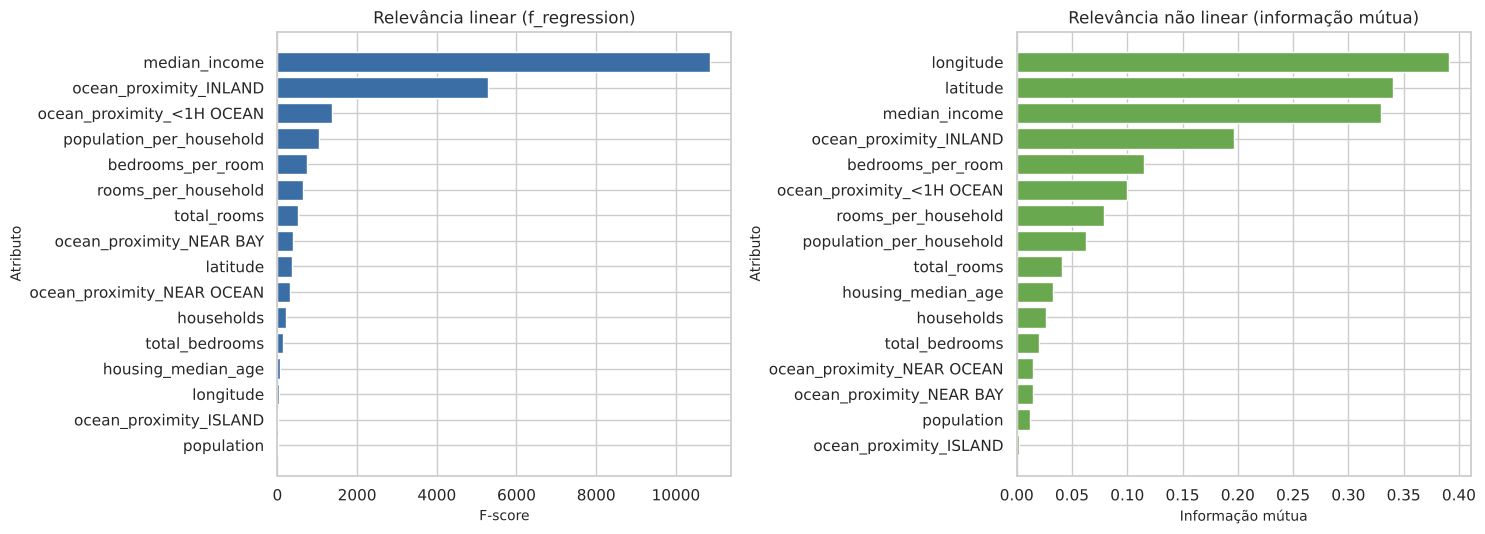

In [16]:
nomes_limpos = [n.split('__', 1)[1] for n in nomes]

f_sc, _ = f_regression(Xt_demo, y_train)                         # relação LINEAR com o alvo
mi = mutual_info_regression(Xt_demo, y_train, random_state=SEED)  # relação QUALQUER (inclui não linear)

ranking = pd.DataFrame({'atributo': nomes_limpos, 'F-score (linear)': f_sc, 'Informação mútua (não linear)': mi})
ranking['posição (F)'] = ranking['F-score (linear)'].rank(ascending=False).astype(int)
ranking['posição (MI)'] = ranking['Informação mútua (não linear)'].rank(ascending=False).astype(int)
display(ranking.sort_values('Informação mútua (não linear)', ascending=False).reset_index(drop=True))

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
r1 = ranking.sort_values('F-score (linear)')
axes[0].barh(r1['atributo'], r1['F-score (linear)'], color='#3b6ea5')
axes[0].set_title('Relevância linear (f_regression)')
axes[0].set_xlabel('F-score')
axes[0].set_ylabel('Atributo')
r2 = ranking.sort_values('Informação mútua (não linear)')
axes[1].barh(r2['atributo'], r2['Informação mútua (não linear)'], color='#6aa84f')
axes[1].set_title('Relevância não linear (informação mútua)')
axes[1].set_xlabel('Informação mútua')
axes[1].set_ylabel('Atributo')
plt.tight_layout()
plt.show()

**Por que dois métodos:** (em linguagem simples, os dois respondem: saber o valor desta variável ajuda a adivinhar o preço?). O `f_regression` só enxerga relação **linear** e cada atributo isolado. A **informação mútua** mede qualquer dependência (inclusive não linear) com o alvo. Comparando os dois rankings dá para ver quais atributos "só aparecem" quando se admite não linearidade, em especial **longitude e latitude**, que passam de 14º e 9º no ranking linear para **1º e 2º** no de informação mútua (já a renda cai de 1º para 3º). Isso antecipa o que as árvores vão explorar na etapa 4.

**Decisão:** ambos são **univariados** e não captam interações (latitude e longitude só localizam a região quando combinadas). Como são poucas variáveis (~16 após o one-hot) e os modelos de árvore lidam bem com atributos pouco informativos, **mantemos todos** e comparamos esses rankings com a importância por permutação (etapa 5).

### Resumo da etapa 3: a "receita" do pré-processamento

```
dados brutos → limpeza → divisão treino/teste → criar features → preencher nulos → log (só variáveis de tamanho) → padronizar → one-hot → modelo
```

| Passo | Por quê |
|---|---|
| Limpar (1.065 linhas removidas) | Tirar o que não é confiável (alvo "travado" no teto e valores absurdos) |
| Dividir **antes** de transformar | O teste precisa ser dado novo; senão há vazamento (seria olhar o gabarito) |
| Variáveis por domicílio | Os totais medem tamanho; as razões descrevem o padrão de moradia |
| Mediana nos nulos | Simples e robusta a outliers |
| Log + padronização | Reduz o peso de valores extremos e deixa tudo na mesma escala (essencial para KNN e Ridge) |
| One-hot em `ocean_proximity` | Categoria sem ordem não pode virar 0, 1, 2 |
| Tudo dentro de um `Pipeline` | Repete exatamente os mesmos passos no treino, na validação cruzada e no teste |

---
# 4. Treinamento dos modelos

> **Em uma frase:** **ensinar vários modelos** com os dados de treino e achar o melhor ajuste de cada um. _Analogia: o treino é estudar com exercícios resolvidos; a validação cruzada são os simulados; o teste é a prova final, feita uma única vez._

### 4.1 Método de treinamento e validação
- **Hold-out:** 80% treino / 20% teste (teste só é usado **uma vez**, no final, para comparar os modelos).
- **Validação cruzada:** `KFold` com 5 dobras (embaralhadas) **dentro do treino**, usada pelo `GridSearchCV`/`RandomizedSearchCV` para escolher hiperparâmetros sem tocar no teste.
- **Métrica de seleção:** RMSE (penaliza mais os erros grandes e está na mesma unidade do alvo, US$).

### 4.2 Modelos (uma de cada família pedida + referências)
| Família | Modelo | Busca de hiperparâmetros |
|---|---|---|
| Referência | `DummyRegressor` (prevê sempre a média) | — |
| Referência | Regressão linear simples (só `median_income`), a mesma ideia vista em aula | — |
| **Linear** | **Ridge** (regressão linear com regularização L2) | `GridSearchCV` |
| **Instância** | **KNN Regressor** | `GridSearchCV` |
| **Árvores / Ensemble** | **Árvore de Decisão** | `GridSearchCV` |
| **Árvores / Ensemble** | **Random Forest** | `RandomizedSearchCV` |
| **Árvores / Ensemble** | **Gradient Boosting** (`HistGradientBoostingRegressor`) | `RandomizedSearchCV` |

In [17]:
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
SCORING = 'neg_root_mean_squared_error'

def rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

resultados_cv = {}      # RMSE médio da validação cruzada (treino)
modelos_finais = {}     # modelos já treinados
melhores_params = {}

# ---- Referência 1: média ----
base_media = montar_pipeline(DummyRegressor(strategy='mean'))
cvs = cross_val_score(base_media, X_train, y_train, cv=cv, scoring=SCORING)
resultados_cv['Baseline (média)'] = -cvs.mean()
modelos_finais['Baseline (média)'] = base_media.fit(X_train, y_train)

# ---- Referência 2: regressão linear simples (só renda) ----
linear_simples = Pipeline([
    ('sel', ColumnTransformer([('renda', 'passthrough', ['median_income'])])),
    ('modelo', LinearRegression()),
])
cvs = cross_val_score(linear_simples, X_train, y_train, cv=cv, scoring=SCORING)
resultados_cv['Regressão linear simples (renda)'] = -cvs.mean()
modelos_finais['Regressão linear simples (renda)'] = linear_simples.fit(X_train, y_train)

pd.Series(resultados_cv, name='RMSE (CV, US$)').to_frame()

,"RMSE (CV, US$)"
Baseline (média),"97,934.484"
Regressão linear simples (renda),"75,271.174"


#### Verificando à mão a regressão linear simples
A reta `y = a·x + b` da aula pode ser calculada sem biblioteca: `a = (n·Σxy − Σx·Σy) / (n·Σx² − (Σx)²)` e `b = (Σy − a·Σx) / n`. Conferimos com o `LinearRegression` (x = `median_income`, y = valor mediano).

In [18]:
x_ = X_train['median_income'].to_numpy()
y_ = y_train.to_numpy()
n_ = len(x_)

a_manual = (n_ * (x_ * y_).sum() - x_.sum() * y_.sum()) / (n_ * (x_ ** 2).sum() - x_.sum() ** 2)
b_manual = (y_.sum() - a_manual * x_.sum()) / n_

print(f'Fórmula manual : a = {a_manual:,.2f} | b = {b_manual:,.2f}')
print(f'LinearRegression: a = {linear_simples.named_steps["modelo"].coef_[0]:,.2f} | b = {linear_simples.named_steps["modelo"].intercept_:,.2f}')
print(f'\nInterpretação: cada +1 na renda mediana (US$ 10 mil) aumenta o valor mediano previsto em ~US$ {a_manual:,.0f}.')

Fórmula manual : a = 39,947.11 | b = 45,886.89
LinearRegression: a = 39,947.11 | b = 45,886.89

Interpretação: cada +1 na renda mediana (US$ 10 mil) aumenta o valor mediano previsto em ~US$ 39,947.


### 4.3 Ridge (modelo linear) — `GridSearchCV`

**Como pensa:** combina todas as variáveis numa soma ponderada (uma reta, ou plano), com um "freio" (`alpha`) para que nenhum peso exagere. Quanto maior o `alpha`, mais freio.

In [19]:
t0 = time.time()
busca_ridge = GridSearchCV(
    montar_pipeline(Ridge(random_state=SEED)),
    param_grid={'modelo__alpha': [0.01, 0.1, 1, 10, 100, 1000]},
    cv=cv, scoring=SCORING, n_jobs=2)
busca_ridge.fit(X_train, y_train)

resultados_cv['Ridge'] = -busca_ridge.best_score_
modelos_finais['Ridge'] = busca_ridge.best_estimator_
melhores_params['Ridge'] = busca_ridge.best_params_
print(f'Ridge | melhores parâmetros: {busca_ridge.best_params_} | RMSE CV: {-busca_ridge.best_score_:,.0f} | {time.time()-t0:.0f}s')

pd.DataFrame(busca_ridge.cv_results_)[['param_modelo__alpha', 'mean_test_score']].assign(
    RMSE=lambda d: -d['mean_test_score']).drop(columns='mean_test_score')

Ridge | melhores parâmetros: {'modelo__alpha': 0.1} | RMSE CV: 58,117 | 2s


,param_modelo__alpha,RMSE
0,0.010,"58,118.566"
1,0.100,"58,117.377"
2,1.000,"58,120.985"
3,10.000,"58,209.821"
4,100.000,"58,673.749"
5,"1,000.000","59,907.230"


### 4.4 KNN Regressor (baseado em instâncias) — `GridSearchCV`

**Intuição (distância euclidiana):** o KNN prevê o preço de uma região olhando para as `k` regiões **mais parecidas** do treino. "Parecida" = menor distância euclidiana: `d = √Σ(xᵢ − yᵢ)²`, a mesma conta feita na planilha dos filmes (vetor − vetor, eleva ao quadrado, soma). Por isso a **escala importa**: sem padronizar, a variável de maior magnitude domina a soma.

In [20]:
# Exemplo com UMA região do teste: quem são as 5 mais parecidas no treino?
x_novo = X_test.iloc[[0]]
print('Região do teste -> valor real: US$', f'{y_test.iloc[0]:,.0f}')

# (a) Distância com dados padronizados (como o pipeline faz)
Xtr_esc = Xt_demo
Xnovo_esc = prep_demo.transform(criar_features(x_novo))
dist = np.sqrt(((Xtr_esc - Xnovo_esc) ** 2).sum(axis=1))
viz = np.argsort(dist)[:5]
tab = X_train.iloc[viz][['longitude', 'latitude', 'median_income', 'ocean_proximity']].copy()
tab['distância'] = dist[viz]
tab['valor (US$)'] = y_train.iloc[viz].to_numpy()
display(tab)
print(f'Média dos 5 vizinhos: US$ {tab["valor (US$)"].mean():,.0f}')

# (b) O que aconteceria SEM padronizar: quanto cada variável pesa na distância
cols_raw = ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'population', 'median_income']
dist_raw = np.sqrt(((X_train[cols_raw].to_numpy() - x_novo[cols_raw].to_numpy()) ** 2).sum(axis=1))
j = np.argmin(dist_raw)
contrib = ((X_train[cols_raw].iloc[j].to_numpy() - x_novo[cols_raw].iloc[0].to_numpy()) ** 2)
print('\nSem padronizar, participação de cada variável na distância ao vizinho mais próximo:')
print(pd.Series(contrib / contrib.sum(), index=cols_raw).map('{:.1%}'.format).to_string())

Região do teste -> valor real: US$ 94,900


,longitude,latitude,median_income,ocean_proximity,distância,valor (US$)
9114,-121.000,37.250,3.174,INLAND,0.635,"97,600.000"
19023,-120.390,38.000,3.212,INLAND,0.723,"105,200.000"
12105,-121.390,38.610,2.463,INLAND,0.801,"156,900.000"
18439,-120.970,37.670,2.400,INLAND,0.862,"121,500.000"
18016,-121.690,38.160,3.294,INLAND,0.898,"96,400.000"


Média dos 5 vizinhos: US$ 115,520

Sem padronizar, participação de cada variável na distância ao vizinho mais próximo:
longitude              2.1%
latitude               1.0%
housing_median_age    54.8%
total_rooms           41.1%
population             1.0%
median_income          0.0%


**Leitura:** (a) com a padronização, os 5 vizinhos são regiões `INLAND` com renda parecida, e o preço previsto vem da média deles. (b) Neste exemplo, **sem padronizar**, quase toda a distância viria de `housing_median_age` (≈ 55%) e `total_rooms` (≈ 41%), enquanto `median_income`, a variável mais associada ao preço, contribuiria com ~0% e latitude/longitude com ~3%. Com a padronização, todas passam a ter peso comparável. É por isso que o `StandardScaler` está no pipeline.

KNN | melhores parâmetros: {'modelo__n_neighbors': 11, 'modelo__p': 1, 'modelo__weights': 'distance'} | RMSE CV: 52,166 | 17s


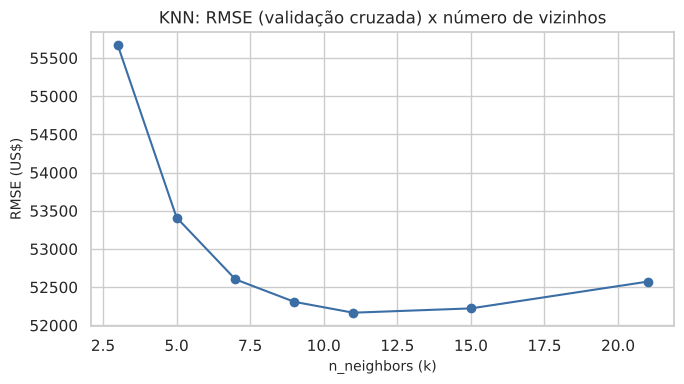

In [21]:
t0 = time.time()
busca_knn = GridSearchCV(
    montar_pipeline(KNeighborsRegressor()),
    param_grid={'modelo__n_neighbors': [3, 5, 7, 9, 11, 15, 21],
                'modelo__weights': ['uniform', 'distance'],
                'modelo__p': [1, 2]},
    cv=cv, scoring=SCORING, n_jobs=2)
busca_knn.fit(X_train, y_train)

resultados_cv['KNN'] = -busca_knn.best_score_
modelos_finais['KNN'] = busca_knn.best_estimator_
melhores_params['KNN'] = busca_knn.best_params_
print(f'KNN | melhores parâmetros: {busca_knn.best_params_} | RMSE CV: {-busca_knn.best_score_:,.0f} | {time.time()-t0:.0f}s')

# Efeito do número de vizinhos (com os demais parâmetros nos melhores valores)
res = pd.DataFrame(busca_knn.cv_results_)
sel = res[(res['param_modelo__weights'] == busca_knn.best_params_['modelo__weights']) &
          (res['param_modelo__p'] == busca_knn.best_params_['modelo__p'])]
plt.figure(figsize=(7, 4))
plt.plot(sel['param_modelo__n_neighbors'].astype(int), -sel['mean_test_score'], marker='o', color='#3b6ea5')
plt.title('KNN: RMSE (validação cruzada) x número de vizinhos')
plt.xlabel('n_neighbors (k)')
plt.ylabel('RMSE (US$)')
plt.tight_layout()
plt.show()

### 4.5 Árvore de Decisão — `GridSearchCV`

**Como pensa:** faz perguntas de sim ou não em sequência ("a renda é maior que 4? a latitude é menor que 34?") até chegar a um preço. `max_depth` limita quantas perguntas pode fazer.

In [22]:
t0 = time.time()
busca_dt = GridSearchCV(
    montar_pipeline(DecisionTreeRegressor(random_state=SEED)),
    param_grid={'modelo__max_depth': [4, 6, 8, 10, 12, 16, None],
                'modelo__min_samples_leaf': [1, 5, 10, 20, 50]},
    cv=cv, scoring=SCORING, n_jobs=2)
busca_dt.fit(X_train, y_train)

resultados_cv['Árvore de Decisão'] = -busca_dt.best_score_
modelos_finais['Árvore de Decisão'] = busca_dt.best_estimator_
melhores_params['Árvore de Decisão'] = busca_dt.best_params_
print(f'Árvore de Decisão | melhores parâmetros: {busca_dt.best_params_} | RMSE CV: {-busca_dt.best_score_:,.0f} | {time.time()-t0:.0f}s')

Árvore de Decisão | melhores parâmetros: {'modelo__max_depth': 12, 'modelo__min_samples_leaf': 20} | RMSE CV: 52,986 | 8s


### 4.6 Random Forest (ensemble de árvores) — `RandomizedSearchCV`

**Como pensa:** treina muitas árvores, cada uma com uma amostra diferente dos dados, e tira a média das respostas. Uma árvore erra; a média de muitas erra menos.

In [23]:
t0 = time.time()
busca_rf = RandomizedSearchCV(
    montar_pipeline(RandomForestRegressor(random_state=SEED, n_jobs=1)),
    param_distributions={'modelo__n_estimators': [100, 200],
                         'modelo__max_depth': [None, 12, 20],
                         'modelo__min_samples_leaf': [1, 2, 5],
                         'modelo__max_features': [0.33, 0.5, 1.0]},
    n_iter=8, cv=cv, scoring=SCORING, n_jobs=2, random_state=SEED)
busca_rf.fit(X_train, y_train)

resultados_cv['Random Forest'] = -busca_rf.best_score_
modelos_finais['Random Forest'] = busca_rf.best_estimator_
melhores_params['Random Forest'] = busca_rf.best_params_
print(f'Random Forest | melhores parâmetros: {busca_rf.best_params_} | RMSE CV: {-busca_rf.best_score_:,.0f} | {time.time()-t0:.0f}s')

Random Forest | melhores parâmetros: {'modelo__n_estimators': 100, 'modelo__min_samples_leaf': 2, 'modelo__max_features': 0.5, 'modelo__max_depth': 20} | RMSE CV: 44,946 | 133s


### 4.7 Gradient Boosting — `RandomizedSearchCV`

**Como pensa:** treina árvores pequenas **em sequência**, e cada nova árvore tenta corrigir o erro que as anteriores deixaram. `learning_rate` controla o tamanho de cada correção.

In [24]:
t0 = time.time()
busca_gb = RandomizedSearchCV(
    montar_pipeline(HistGradientBoostingRegressor(random_state=SEED)),
    param_distributions={'modelo__learning_rate': [0.03, 0.05, 0.1, 0.2],
                         'modelo__max_iter': [200, 400, 600],
                         'modelo__max_leaf_nodes': [15, 31, 63],
                         'modelo__min_samples_leaf': [10, 20, 40],
                         'modelo__l2_regularization': [0, 0.1, 1.0]},
    n_iter=15, cv=cv, scoring=SCORING, n_jobs=2, random_state=SEED)
busca_gb.fit(X_train, y_train)

resultados_cv['Gradient Boosting'] = -busca_gb.best_score_
modelos_finais['Gradient Boosting'] = busca_gb.best_estimator_
melhores_params['Gradient Boosting'] = busca_gb.best_params_
print(f'Gradient Boosting | melhores parâmetros: {busca_gb.best_params_} | RMSE CV: {-busca_gb.best_score_:,.0f} | {time.time()-t0:.0f}s')

Gradient Boosting | melhores parâmetros: {'modelo__min_samples_leaf': 20, 'modelo__max_leaf_nodes': 63, 'modelo__max_iter': 400, 'modelo__learning_rate': 0.03, 'modelo__l2_regularization': 0.1} | RMSE CV: 41,772 | 24s


### Resumo da etapa 4: o que aprendemos treinando

| Modelo | Como "pensa" | Melhor ajuste | RMSE na validação cruzada (US$) |
|---|---|---|---|
| Ridge | Soma ponderada das variáveis, com freio | `alpha` = 0,1 | ≈ 58,1 mil |
| KNN | Olha os vizinhos mais parecidos | k = 11, pesos por distância | ≈ 52,2 mil |
| Árvore de Decisão | Perguntas de sim ou não em sequência | profundidade 12 | ≈ 53,0 mil |
| Random Forest | Muitas árvores votando | 100 árvores, profundidade 20 | ≈ 44,9 mil |
| Gradient Boosting | Árvores em sequência corrigindo erros | taxa 0,03, 400 iterações | ≈ 41,8 mil |

Quanto **menor** o RMSE, melhor. Os dois modelos que combinam muitas árvores (Random Forest e Gradient Boosting) levam clara vantagem.

---
# 5. Avaliação, benchmark e conclusão

> **Em uma frase:** **comparar os modelos com honestidade** (no teste, que eles nunca viram) e dizer o que o resultado significa na prática.

### 5.1 Métricas
Usamos as métricas de regressão: **MAE** (erro médio absoluto), **MSE** (erro quadrático médio), **RMSE** (raiz do MSE, em US$), **R²** (parcela da variância explicada), além de **MAPE** (erro percentual médio) e **MedAE** (erro absoluto mediano). Todas são calculadas no **conjunto de teste**, que os modelos nunca viram. O R² de treino serve para checar _overfitting_.

**Como ler cada métrica (em linguagem simples):**

| Métrica | Pergunta que responde | Como interpretar |
|---|---|---|
| MAE | "Em média, quantos dólares o modelo erra?" | Menor é melhor |
| MSE | Média dos erros ao quadrado (pune os erros grandes) | Usada para chegar ao RMSE |
| RMSE | O MSE de volta à unidade de dólares | Menor é melhor; pesa mais os erros grandes |
| R² | "Que parte da variação dos preços o modelo explica?" | 1 = perfeito; 0 = igual a chutar sempre a média |
| MAPE | Erro médio em % do preço real | 16% = erra, em média, 16% do valor |
| MedAE | Erro "típico", sem influência de erros extremos | Menor é melhor |

In [25]:
def avaliar(nome, modelo):
    p_te = modelo.predict(X_test)
    p_tr = modelo.predict(X_train)
    return {
        'Modelo': nome,
        'RMSE CV (treino)': resultados_cv[nome],
        'MAE': mean_absolute_error(y_test, p_te),
        'MSE': mean_squared_error(y_test, p_te),
        'RMSE': rmse(y_test, p_te),
        'R²': r2_score(y_test, p_te),
        'MAPE (%)': mean_absolute_percentage_error(y_test, p_te) * 100,
        'MedAE': median_absolute_error(y_test, p_te),
        'R² treino': r2_score(y_train, p_tr),
    }

tabela = pd.DataFrame([avaliar(n, m) for n, m in modelos_finais.items()]).set_index('Modelo')
tabela = tabela.sort_values('RMSE')
tabela.style.format({'RMSE CV (treino)': '{:,.0f}', 'MAE': '{:,.0f}', 'MSE': '{:,.3e}', 'RMSE': '{:,.0f}',
                     'R²': '{:.3f}', 'MAPE (%)': '{:.1f}', 'MedAE': '{:,.0f}', 'R² treino': '{:.3f}'}
                    ).background_gradient(subset=['RMSE'], cmap='Greens_r')

,RMSE CV (treino),MAE,MSE,RMSE,R²,MAPE (%),MedAE,R² treino
Modelo,,,,,,,,
Gradient Boosting,"41,772","27,191",1.649e+09,"40,609",0.825,16.0,"18,037",0.909
Random Forest,"44,946","29,532",1.928e+09,"43,904",0.795,17.3,"19,477",0.950
Árvore de Decisão,"52,986","35,514",2.609e+09,"51,077",0.723,20.7,"23,840",0.798
KNN,"52,166","35,466",2.637e+09,"51,349",0.720,20.9,"24,030",1.000
Ridge,"58,117","42,017",3.208e+09,"56,639",0.660,26.6,"32,237",0.649
Regressão linear simples (renda),"75,271","55,927",5.290e+09,"72,730",0.439,36.9,"45,399",0.409
Baseline (média),"97,934","77,806",9.424e+09,"97,079",-0.000,56.2,"66,653",0.000


### 5.2 Benchmark entre os modelos

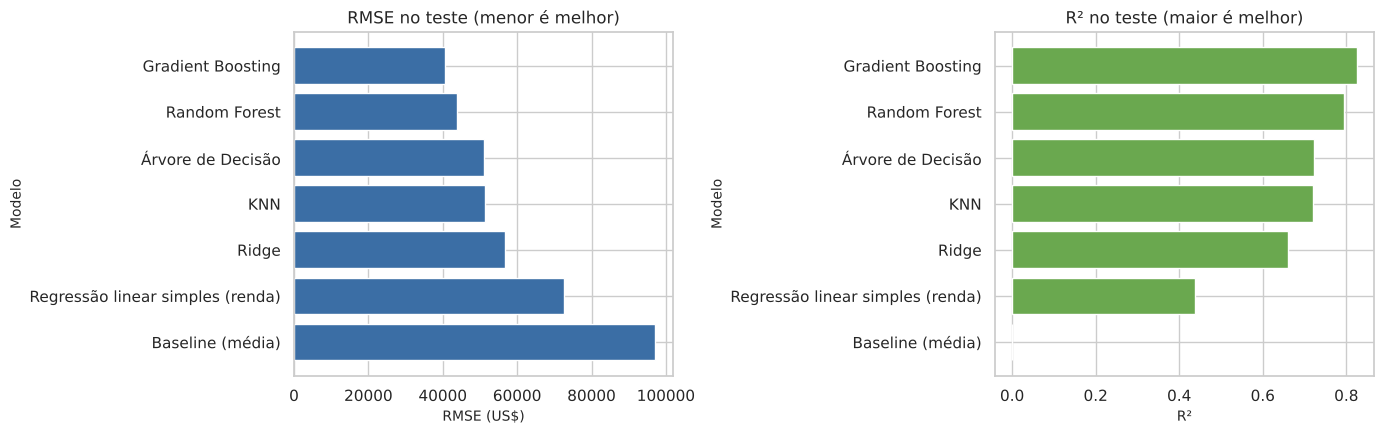

Modelo final (menor RMSE na validação cruzada): Gradient Boosting
Hiperparâmetros: {'modelo__min_samples_leaf': 20, 'modelo__max_leaf_nodes': 63, 'modelo__max_iter': 400, 'modelo__learning_rate': 0.03, 'modelo__l2_regularization': 0.1}


In [26]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
ordem = tabela.index.tolist()
axes[0].barh(ordem[::-1], tabela['RMSE'][::-1], color='#3b6ea5')
axes[0].set_title('RMSE no teste (menor é melhor)')
axes[0].set_xlabel('RMSE (US$)')
axes[0].set_ylabel('Modelo')
axes[1].barh(ordem[::-1], tabela['R²'][::-1], color='#6aa84f')
axes[1].set_title('R² no teste (maior é melhor)')
axes[1].set_xlabel('R²')
axes[1].set_ylabel('Modelo')
plt.tight_layout()
plt.show()

# Escolha do modelo final: menor RMSE de validação cruzada entre os modelos ajustados (decisão feita SEM olhar o teste)
candidatos = ['Ridge', 'KNN', 'Árvore de Decisão', 'Random Forest', 'Gradient Boosting']
nome_final = min(candidatos, key=lambda n: resultados_cv[n])
modelo_final = modelos_finais[nome_final]
print('Modelo final (menor RMSE na validação cruzada):', nome_final)
print('Hiperparâmetros:', melhores_params[nome_final])

### 5.3 Diagnóstico do modelo final

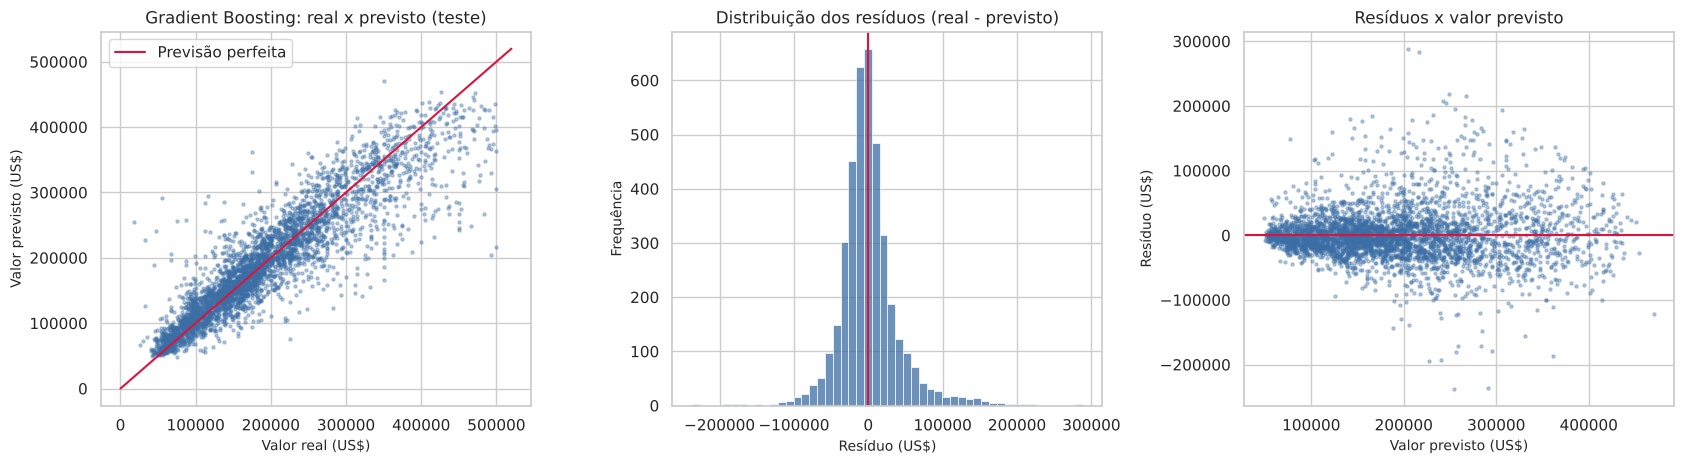

In [27]:
pred = modelo_final.predict(X_test)
res_ = y_test - pred

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))

lim = [0, 520000]
axes[0].scatter(y_test, pred, s=5, alpha=.35, color='#3b6ea5')
axes[0].plot(lim, lim, color='crimson', lw=1.5, label='Previsão perfeita')
axes[0].set_title(f'{nome_final}: real x previsto (teste)')
axes[0].set_xlabel('Valor real (US$)')
axes[0].set_ylabel('Valor previsto (US$)')
axes[0].legend()

sns.histplot(res_, bins=50, ax=axes[1], color='#3b6ea5')
axes[1].axvline(0, color='crimson')
axes[1].set_title('Distribuição dos resíduos (real - previsto)')
axes[1].set_xlabel('Resíduo (US$)')
axes[1].set_ylabel('Frequência')

axes[2].scatter(pred, res_, s=5, alpha=.35, color='#3b6ea5')
axes[2].axhline(0, color='crimson')
axes[2].set_title('Resíduos x valor previsto')
axes[2].set_xlabel('Valor previsto (US$)')
axes[2].set_ylabel('Resíduo (US$)')
plt.tight_layout()
plt.show()

### 5.4 Quais atributos mais pesam? (importância por permutação)

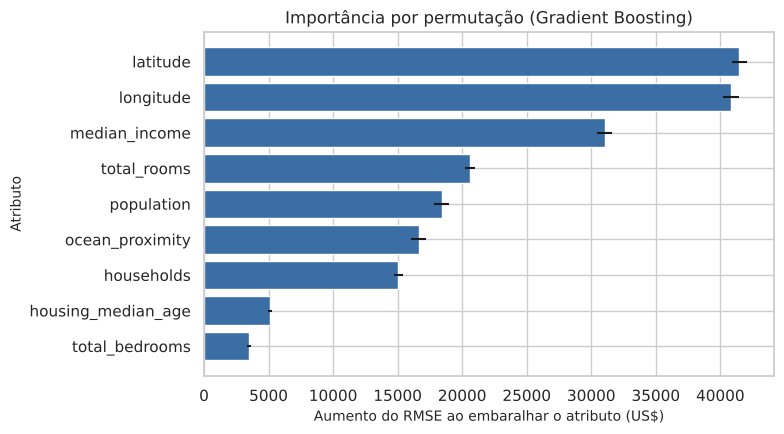

latitude             41,485.000
longitude            40,831.000
median_income        31,029.000
total_rooms          20,607.000
population           18,412.000
ocean_proximity      16,617.000
households           15,057.000
housing_median_age    5,106.000
total_bedrooms        3,502.000
dtype: float64

In [28]:
perm = permutation_importance(modelo_final, X_test, y_test, scoring=SCORING, n_repeats=5,
                              random_state=SEED, n_jobs=2)
imp = pd.Series(perm.importances_mean, index=X_test.columns).sort_values()

plt.figure(figsize=(8, 4.5))
plt.barh(imp.index, imp.values, xerr=pd.Series(perm.importances_std, index=X_test.columns)[imp.index], color='#3b6ea5')
plt.title(f'Importância por permutação ({nome_final})')
plt.xlabel('Aumento do RMSE ao embaralhar o atributo (US$)')
plt.ylabel('Atributo')
plt.tight_layout()
plt.show()
imp.sort_values(ascending=False).round(0)

### 5.5 Onde o modelo erra mais?

In [29]:
analise = pd.DataFrame({'real': y_test, 'previsto': pred, 'proximidade': X_test['ocean_proximity']})
analise['erro_abs'] = (analise['real'] - analise['previsto']).abs()
analise['erro_pct'] = analise['erro_abs'] / analise['real'] * 100
analise['faixa_preco'] = pd.qcut(analise['real'], 4, labels=['25% mais baratas', '2º quartil', '3º quartil', '25% mais caras'])

print('Erro por faixa de preço real:')
display(analise.groupby('faixa_preco', observed=True)[['erro_abs', 'erro_pct']].mean().round(1))
print('Erro por proximidade do oceano:')
por_prox = analise.groupby('proximidade').agg(erro_abs=('erro_abs', 'mean'), erro_pct=('erro_pct', 'mean'), n=('real', 'size'))
display(por_prox.round(1))

Erro por faixa de preço real:


,erro_abs,erro_pct
faixa_preco,,
25% mais baratas,"18,411.400",24.500
2º quartil,"20,577.200",14.100
3º quartil,"24,676.800",12.000
25% mais caras,"45,125.600",13.400


Erro por proximidade do oceano:


,erro_abs,erro_pct,n
proximidade,,,
<1H OCEAN,"29,026.700",14.600,1699
INLAND,"20,907.000",17.500,1314
ISLAND,"91,592.400",26.800,2
NEAR BAY,"32,568.800",17.400,404
NEAR OCEAN,"32,911.100",15.600,496


### 5.6 Visão de classificação: acurácia e matriz de confusão por faixa de preço
Para o time de negócio, muitas vezes importa mais **em que faixa de preço** a região está (baixa, média ou alta) do que o valor exato. Convertemos o preço real e o previsto em 3 faixas, usando os **tercis do treino** como cortes (as mesmas faixas para todos os modelos), e aplicamos as métricas de classificação vistas em aula: **acurácia**, **matriz de confusão**, e precisão/recall por faixa.

Cortes das faixas: Baixo < US$ 137,500 <= Médio < US$ 221,133 <= Alto


,Acurácia por faixa
Gradient Boosting,80.8%
Random Forest,79.6%
KNN,75.5%
Árvore de Decisão,74.4%
Ridge,70.1%
Regressão linear simples (renda),57.2%
Baseline (média),34.4%


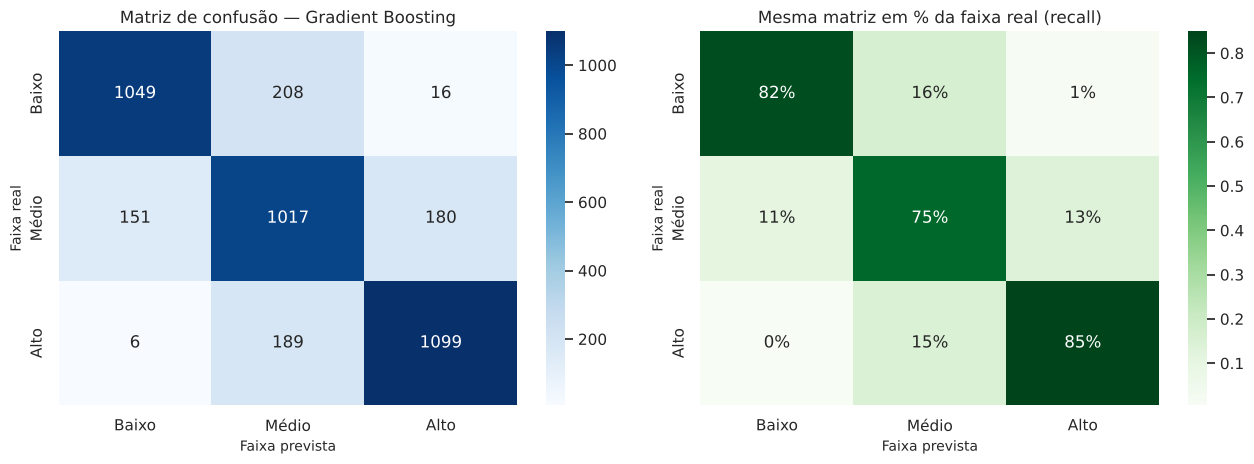

              precision    recall  f1-score   support

       Baixo      0.870     0.824     0.846      1273
       Médio      0.719     0.754     0.736      1348
        Alto      0.849     0.849     0.849      1294

    accuracy                          0.808      3915
   macro avg      0.813     0.809     0.811      3915
weighted avg      0.811     0.808     0.809      3915



In [30]:
cortes = y_train.quantile([1/3, 2/3]).to_numpy()
nomes_faixas = ['Baixo', 'Médio', 'Alto']
def para_faixa(v):
    return pd.cut(v, bins=[-np.inf, cortes[0], cortes[1], np.inf], labels=nomes_faixas)

print(f'Cortes das faixas: Baixo < US$ {cortes[0]:,.0f} <= Médio < US$ {cortes[1]:,.0f} <= Alto')

# Acurácia por modelo (o modelo continua sendo de regressão; só agrupamos o resultado)
acc = {n: accuracy_score(para_faixa(y_test), para_faixa(m.predict(X_test))) for n, m in modelos_finais.items()}
display(pd.Series(acc, name='Acurácia por faixa').sort_values(ascending=False).to_frame().style.format('{:.1%}'))

# Matriz de confusão e relatório do modelo final
real_f = para_faixa(y_test)
prev_f = para_faixa(pred)
cm = confusion_matrix(real_f, prev_f, labels=nomes_faixas)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=nomes_faixas, yticklabels=nomes_faixas, ax=axes[0])
axes[0].set_title(f'Matriz de confusão — {nome_final}')
axes[0].set_xlabel('Faixa prevista')
axes[0].set_ylabel('Faixa real')
sns.heatmap(cm / cm.sum(axis=1, keepdims=True), annot=True, fmt='.0%', cmap='Greens',
            xticklabels=nomes_faixas, yticklabels=nomes_faixas, ax=axes[1])
axes[1].set_title('Mesma matriz em % da faixa real (recall)')
axes[1].set_xlabel('Faixa prevista')
axes[1].set_ylabel('Faixa real')
plt.tight_layout()
plt.show()

print(classification_report(real_f, prev_f, labels=nomes_faixas, digits=3))

### 5.7 Discussão dos resultados

_(Números abaixo obtidos com `SEED = 42`; se rodar novamente com outra versão de bibliotecas, valores podem variar um pouco.)_

**Benchmark.** No conjunto de teste, o ranking foi: **Gradient Boosting** (RMSE ≈ US$ 40,6 mil; R² = 0,825) > Random Forest (≈ 43,9 mil; 0,795) > Árvore de Decisão (≈ 51,1 mil; 0,723) ≈ KNN (≈ 51,3 mil; 0,720) > Ridge (≈ 56,6 mil; 0,660) > regressão linear simples com renda (≈ 72,7 mil; 0,439) > média (≈ 97,1 mil; 0,000). Árvore de Decisão e KNN ficaram empatados (na validação cruzada o KNN foi um pouco melhor, no teste a árvore). O topo do ranking (Gradient Boosting, depois Random Forest) é o mesmo na validação cruzada e no teste, o que dá confiança de que a escolha não depende do acaso da divisão treino/teste.

**Por que modelos de árvore vencem aqui.** A relação entre as variáveis e o preço é **não linear e espacial** (seção 2.7): o efeito da renda depende de onde a região está. O Ridge só consegue somar efeitos lineares; o KNN usa vizinhança, mas sofre com a escala de várias variáveis; os modelos de árvore capturam interações (ex.: latitude × longitude × renda) naturalmente, e **combinar muitas árvores** (Random Forest, Gradient Boosting) reduz bastante o erro de uma árvore sozinha (RMSE de ≈ 51 mil para ≈ 41 mil). A informação mútua (3.6) e a importância por permutação (5.4) confirmam: **latitude, longitude e renda mediana** são as que mais pesam. Note a diferença em relação ao `f_regression`, em que longitude e latitude apareciam fracas: sozinhas e sob uma ótica linear elas dizem pouco, mas **combinadas** localizam a região.

**Sub e sobreajuste.**
- Ridge: R² treino (0,649) ≈ teste (0,660) → _underfitting_ (o modelo é simples demais para o problema).
- KNN (com pesos por distância): R² treino = 1,00 contra 0,72 no teste → memoriza o treino.
- Árvore de Decisão: 0,798 contra 0,723 → sobreajuste moderado (a profundidade e o tamanho mínimo da folha foram limitados pela busca).
- Random Forest: 0,950 no treino contra 0,795 no teste → algum _overfitting_.
- Gradient Boosting: 0,909 contra 0,825 → menor distância entre treino e teste, com a melhor generalização.

**Visão por faixa de preço (classificação).** Agrupando os valores em três faixas (Baixo, Médio, Alto), o Gradient Boosting acerta a faixa em **80,8%** das regiões do teste (Random Forest 79,6%, KNN 75,5%, Árvore 74,4%, Ridge 70,1%; prever sempre a média acerta só 34,4%, o que é o esperado ao acaso com 3 faixas). Pela matriz de confusão, o recall é de 82% (Baixo), 75% (Médio) e 85% (Alto). **Os erros se concentram em faixas vizinhas**: só 16 regiões de faixa Baixa foram classificadas como Alta e 6 de faixa Alta como Baixa. Ou seja, quando erra, o modelo erra "para o lado", e a faixa do meio é a mais difícil.

**Onde o modelo erra mais.**
- Em valor absoluto, erra mais nas regiões **mais caras** (MAE ≈ US$ 45 mil no quartil superior) e tende a **subestimá-las** (gráfico real × previsto, seção 5.3).
- Em percentual, erra mais nas regiões **mais baratas** (MAPE ≈ 24,5% no quartil inferior), em que um erro pequeno em dólares pesa mais.
- Por proximidade do oceano, o erro é parecido entre as categorias principais (≈ 15% a 17,5%); `ISLAND` tem só 2 registros no teste e não permite conclusão.

### 5.8 Possíveis melhorias
1. **Transformar o alvo** (log de `median_house_value`, via `TransformedTargetRegressor`) para reduzir o erro percentual nas regiões baratas e a assimetria dos resíduos.
2. **Features espaciais:** distância até a costa e às grandes cidades (San Francisco, Los Angeles, San Diego) ou _clusters_ de latitude/longitude. A localização é o fator mais importante e hoje entra só como coordenadas brutas.
3. **Busca de hiperparâmetros mais ampla** (mais iterações, ou Optuna) e outros ensembles (XGBoost, LightGBM, _stacking_ com Ridge + KNN + árvores).
4. **Para o Ridge:** `PolynomialFeatures` para captar interações, já que ele sofre de _underfitting_.
5. **Dados mais recentes** e com mais variáveis (qualidade da escola, criminalidade, tipo de imóvel), pois a base é de 1990 e agrega regiões inteiras.
6. **Intervalos de previsão** (ex.: regressão quantílica) para informar a incerteza junto com o valor.

### 5.9 Conclusão
O objetivo era estimar o **valor mediano das casas de uma região da Califórnia** a partir de características demográficas e geográficas. O modelo escolhido foi o **Gradient Boosting**, que reduziu o RMSE em cerca de **58% em relação a prever sempre a média** (≈ US$ 97 mil → 40,6 mil) e em cerca de **28% em relação ao melhor modelo linear** (Ridge). Ele explica **82,5% da variância** do preço, erra, em média, **US$ 27 mil (≈ 16%)** e acerta a **faixa de preço** (baixa, média ou alta) em **80,8%** dos casos, quase sempre errando só para a faixa vizinha.

**Atende às expectativas?** Como referência de preço para uma região, sim: o erro típico é de uma ordem de grandeza compatível com triagem, comparação entre regiões e identificação de áreas que fogem do esperado. **Não** é adequado para avaliar um imóvel individual nem para decisões de crédito sem validação adicional, pois:
- cada linha é uma **região**, não uma casa;
- os dados são de **1990**;
- retiramos os valores no teto de US$ 500 mil, então o modelo **não deve ser usado para regiões acima desse patamar**;
- ele **subestima as regiões mais caras**.

**Implicação prática:** o preço é determinado principalmente por **onde** a região fica e pela **renda** de quem mora ali. Isso sugere que o maior ganho futuro está em melhorar a representação da localização (melhoria 2) antes de trocar de algoritmo.